
# Salon Experiment & Causal Analysis

## Customer Retention Improvement Through Appointment Reminders

### Project Overview
This project demonstrates the application of experimentation
and causal inference techniques to evaluate a customer retention
intervention for a fictional salon business.

### Business Objective
Evaluate whether appointment reminders improve customer
retention within 60 days.

### Analytical Methods
- Exploratory Data Analysis
- Statistical Power Analysis
- Randomization and SRM Validation
- A/B Testing
- Customer Segment Analysis
- Holm Multiple-Testing Correction
- CUPED Variance Reduction
- Difference-in-Differences

### Technology Stack
Python | Pandas | NumPy | SciPy | Statsmodels |
Matplotlib | Seaborn | Jupyter Notebook

### Important Data Disclaimer
All datasets and outcomes in this project are synthetic.
They are created for analytical demonstration and do not
represent actual salon business performance.


In [34]:
# Import libraries and configure project paths

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

# Works whether Jupyter starts in the project root or notebooks/.
cwd = Path.cwd()
candidates = [cwd, cwd.parent]
ROOT = next(
    (p for p in candidates if (p / "data" / "synthetic").exists()),
    cwd.parent
)

DATA = ROOT / "data"
PROCESSED = DATA / "processed"
SYNTHETIC = DATA / "synthetic"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print("Project environment initialized successfully.")
print("Project root:", ROOT)


Project environment initialized successfully.
Project root: s:\Projects\Salon-Experiment-Causal-Analysis


In [35]:
# Load the synthetic datasets

required_files = {
    "appointments": SYNTHETIC / "appointments.csv",
    "customers": SYNTHETIC / "customers.csv",
    "outlets": SYNTHETIC / "outlets.csv",
    "ab_test": PROCESSED / "synthetic_experiment_outcomes.csv",
    "cuped": PROCESSED / "synthetic_cuped_scenario.csv",
    "did": PROCESSED / "synthetic_outlet_monthly_did.csv",
}

missing_files = [str(path) for path in required_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required project data files were not found. Check the project root and files:\n"
        + "\n".join(missing_files)
    )

appointments = pd.read_csv(required_files["appointments"])
customers = pd.read_csv(required_files["customers"])
outlets = pd.read_csv(required_files["outlets"])
ab_test = pd.read_csv(required_files["ab_test"])
cuped = pd.read_csv(required_files["cuped"])
did = pd.read_csv(required_files["did"], parse_dates=["month"])

print("All datasets loaded successfully.")
for name, frame in {
    "Appointments": appointments,
    "Customers": customers,
    "Outlets": outlets,
    "A/B experiment": ab_test,
    "CUPED scenario": cuped,
    "DiD scenario": did,
}.items():
    print(f"{name}: {frame.shape}")


All datasets loaded successfully.
Appointments: (300000, 17)
Customers: (40000, 5)
Outlets: (22, 4)
A/B experiment: (40000, 12)
CUPED scenario: (40000, 14)
DiD scenario: (660, 5)



# 1. Exploratory Data Analysis (EDA)

## Objective
Understand the structure, quality, distributions and patterns
within the synthetic salon appointment dataset.

### Areas of investigation
- Dataset dimensions and data types
- Missing values
- Duplicate records
- Appointment status distribution
- Customer and outlet activity
- Revenue distribution
- Numerical summary statistics


In [36]:
# Dataset overview

print("APPOINTMENT DATASET OVERVIEW")
print("=" * 55)

print("Rows:", appointments.shape[0])
print("Columns:", appointments.shape[1])

display(appointments.head())

print("\nDATA TYPES")
display(appointments.dtypes.to_frame("Data Type"))

print("\nSTATISTICAL SUMMARY")
display(appointments.describe(include="all").T)

APPOINTMENT DATASET OVERVIEW
Rows: 300000
Columns: 17


,appointment_id,is_walk_in,customer_id,outlet_id,stylist_id,appointment_date,service_id,raw_service_name,appointment_status,is_no_show,is_cancellation,revenue,experiment_group,experiment_treatment,returned_within_60d,historical_treatment,historical_post
0,A000001,0,C16356,O15,S037,2026-06-13,SV05,Foot Care,Completed,0,0,754.5300,Control,0,NaN,0,1
1,A000002,0,C29451,O21,S021,2026-01-01,SV01,Cutting,Cancelled,1,1,0.0000,Treatment,1,NaN,0,1
2,A000003,0,C39302,O05,S027,2026-02-21,SV05,Foot Care,Completed,0,0,754.0100,Treatment,1,1.0000,1,1
3,A000004,0,C15613,O05,S071,2025-08-23,SV05,Feet Treatment,Completed,0,0,601.7800,Treatment,1,0.0000,1,0
4,A000005,0,C20589,O17,S017,2025-07-31,SV01,Haircut,Completed,0,0,555.4500,Treatment,1,1.0000,0,0



DATA TYPES


,Data Type
appointment_id,object
is_walk_in,int64
customer_id,object
outlet_id,object
stylist_id,object
appointment_date,object
service_id,object
raw_service_name,object
appointment_status,object
is_no_show,int64



STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
appointment_id,300000,300000,A299984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_walk_in,300000.0000,NaN,NaN,NaN,0.0799,0.2712,0.0000,0.0000,0.0000,0.0000,1.0000
customer_id,276016,39966,C06646,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
outlet_id,300000,22,O15,14164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stylist_id,300000,110,S052,2884,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_date,300000,546,2025-11-06,636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_id,300000,6,SV01,89949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
raw_service_name,300000,18,Cutting,30019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_status,300000,3,Completed,273370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_no_show,300000.0000,NaN,NaN,NaN,0.0888,0.2844,0.0000,0.0000,0.0000,0.0000,1.0000


In [37]:
# Missing values

missing_summary = pd.DataFrame({
    "Missing Values": appointments.isnull().sum(),
    "Missing Percentage": (
        appointments.isnull().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

print("MISSING VALUE ANALYSIS")
display(missing_summary)

# Duplicate records
print("\nDuplicate Rows:", appointments.duplicated().sum())

# Unique values
print("\nUNIQUE VALUES")
display(
    appointments.nunique().to_frame("Unique Values")
)

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
returned_within_60d,75885,25.2950
customer_id,23984,7.9947
appointment_id,0,0.0000
outlet_id,0,0.0000
is_walk_in,0,0.0000
appointment_date,0,0.0000
service_id,0,0.0000
raw_service_name,0,0.0000
stylist_id,0,0.0000
appointment_status,0,0.0000



Duplicate Rows: 0

UNIQUE VALUES


,Unique Values
appointment_id,300000
is_walk_in,2
customer_id,39966
outlet_id,22
stylist_id,110
appointment_date,546
service_id,6
raw_service_name,18
appointment_status,3
is_no_show,2


## EDA: Appointment status and operational metrics

Use `appointment_status` as the source of truth for Completed, Cancelled and No-show categories. The generated `is_no_show` flag is inconsistent: it marks both Cancelled and No-show records. We retain the original column for audit purposes but do not use it to calculate the no-show KPI.


In [38]:
# Dataset schema and a sample of records

print("APPOINTMENT DATASET COLUMNS")
for i, column in enumerate(appointments.columns, start=1):
    print(f"{i}. {column}")

display(appointments.head())


APPOINTMENT DATASET COLUMNS
1. appointment_id
2. is_walk_in
3. customer_id
4. outlet_id
5. stylist_id
6. appointment_date
7. service_id
8. raw_service_name
9. appointment_status
10. is_no_show
11. is_cancellation
12. revenue
13. experiment_group
14. experiment_treatment
15. returned_within_60d
16. historical_treatment
17. historical_post


,appointment_id,is_walk_in,customer_id,outlet_id,stylist_id,appointment_date,service_id,raw_service_name,appointment_status,is_no_show,is_cancellation,revenue,experiment_group,experiment_treatment,returned_within_60d,historical_treatment,historical_post
0,A000001,0,C16356,O15,S037,2026-06-13,SV05,Foot Care,Completed,0,0,754.5300,Control,0,NaN,0,1
1,A000002,0,C29451,O21,S021,2026-01-01,SV01,Cutting,Cancelled,1,1,0.0000,Treatment,1,NaN,0,1
2,A000003,0,C39302,O05,S027,2026-02-21,SV05,Foot Care,Completed,0,0,754.0100,Treatment,1,1.0000,1,1
3,A000004,0,C15613,O05,S071,2025-08-23,SV05,Feet Treatment,Completed,0,0,601.7800,Treatment,1,0.0000,1,0
4,A000005,0,C20589,O17,S017,2025-07-31,SV01,Haircut,Completed,0,0,555.4500,Treatment,1,1.0000,0,0


In [39]:
# Data quality summary

missing_summary = pd.DataFrame({
    "Missing Values": appointments.isna().sum(),
    "Missing Percentage": appointments.isna().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)
print("Duplicate full rows:", appointments.duplicated().sum())
print("Duplicate appointment IDs:", appointments["appointment_id"].duplicated().sum())


,Missing Values,Missing Percentage
returned_within_60d,75885,25.2950
customer_id,23984,7.9947
appointment_id,0,0.0000
outlet_id,0,0.0000
is_walk_in,0,0.0000
appointment_date,0,0.0000
service_id,0,0.0000
raw_service_name,0,0.0000
stylist_id,0,0.0000
appointment_status,0,0.0000


Duplicate full rows: 0
Duplicate appointment IDs: 0


,Status,Appointments,Percentage
0,Completed,273370,91.1233
1,Cancelled,17259,5.7530
2,No-show,9371,3.1237


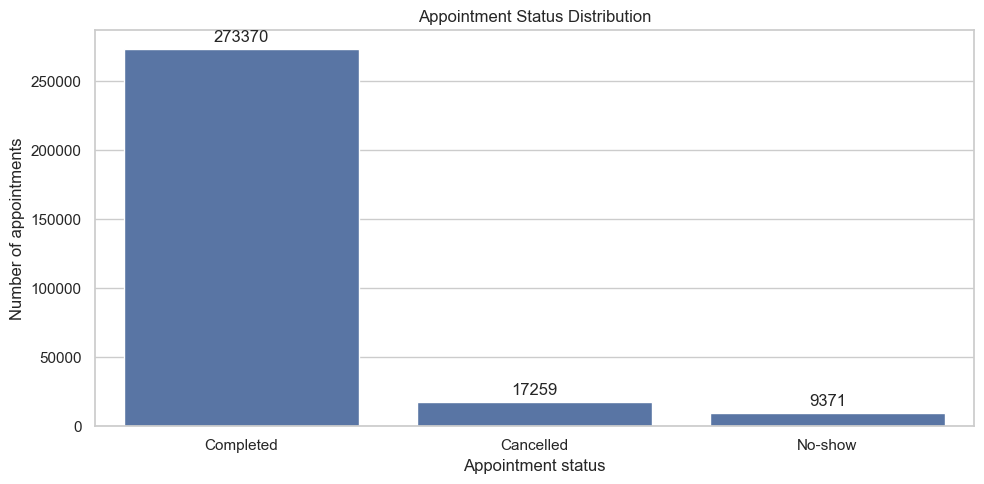

In [40]:
# Appointment status distribution

status_summary = (
    appointments["appointment_status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Appointments")
)
status_summary["Percentage"] = (
    status_summary["Appointments"] / len(appointments) * 100
)
display(status_summary)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=status_summary, x="Status", y="Appointments", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set(title="Appointment Status Distribution",
       xlabel="Appointment status", ylabel="Number of appointments")
plt.tight_layout()
plt.savefig(FIGURES / "appointment_status_distribution.png", dpi=200)
plt.show()


In [41]:
# Operational KPIs — derive categories from appointment_status

total_appointments = len(appointments)
status_counts = appointments["appointment_status"].value_counts()

operational_metrics = pd.DataFrame({
    "Metric": [
        "Total appointments",
        "Walk-in appointments",
        "Completed appointments",
        "Cancelled appointments",
        "No-show appointments",
    ],
    "Count": [
        total_appointments,
        int(appointments["is_walk_in"].sum()),
        int(status_counts.get("Completed", 0)),
        int(status_counts.get("Cancelled", 0)),
        int(status_counts.get("No-show", 0)),
    ],
})

operational_metrics["Percentage of all appointments"] = (
    operational_metrics["Count"] / total_appointments * 100
)
display(operational_metrics)

# Audit the generated indicator flags against the status field.
flag_audit = pd.DataFrame({
    "Check": [
        "is_no_show = 1",
        "is_cancellation = 1",
        "Status is No-show",
        "Status is Cancelled",
    ],
    "Count": [
        int(appointments["is_no_show"].sum()),
        int(appointments["is_cancellation"].sum()),
        int((appointments["appointment_status"] == "No-show").sum()),
        int((appointments["appointment_status"] == "Cancelled").sum()),
    ],
})
display(flag_audit)


,Metric,Count,Percentage of all appointments
0,Total appointments,300000,100.0000
1,Walk-in appointments,23984,7.9947
2,Completed appointments,273370,91.1233
3,Cancelled appointments,17259,5.7530
4,No-show appointments,9371,3.1237


,Check,Count
0,is_no_show = 1,26630
1,is_cancellation = 1,17259
2,Status is No-show,9371
3,Status is Cancelled,17259


**Data-quality finding:** `is_no_show` marks both Cancelled and No-show appointments (26,630 rows), while `appointment_status` distinguishes them (9,371 No-show and 17,259 Cancelled). Therefore, status-derived counts are used for reporting. The source data is not overwritten.


In [42]:
# Revenue analysis — all records and completed appointments separately

appointments["revenue"] = pd.to_numeric(appointments["revenue"], errors="coerce")
completed = appointments.loc[
    appointments["appointment_status"].eq("Completed")
].copy()

revenue_summary = pd.DataFrame({
    "Metric": [
        "All-record revenue sum",
        "Completed appointment revenue",
        "Average revenue per completed appointment",
        "Median revenue per completed appointment",
        "Revenue on non-completed appointments",
    ],
    "Value": [
        appointments["revenue"].sum(),
        completed["revenue"].sum(),
        completed["revenue"].mean(),
        completed["revenue"].median(),
        appointments.loc[
            ~appointments["appointment_status"].eq("Completed"), "revenue"
        ].sum(),
    ],
})
display(revenue_summary)
display(completed["revenue"].describe().to_frame("Completed appointment revenue"))


,Metric,Value
0,All-record revenue sum,298909829.4600
1,Completed appointment revenue,298909829.4600
2,Average revenue per completed appointment,1093.4259
3,Median revenue per completed appointment,800.8150
4,Revenue on non-completed appointments,0.0000


,Completed appointment revenue
count,273370.0000
mean,1093.4259
std,613.3269
min,248.3500
25%,555.2700
50%,800.8150
75%,1633.7350
max,3288.2700


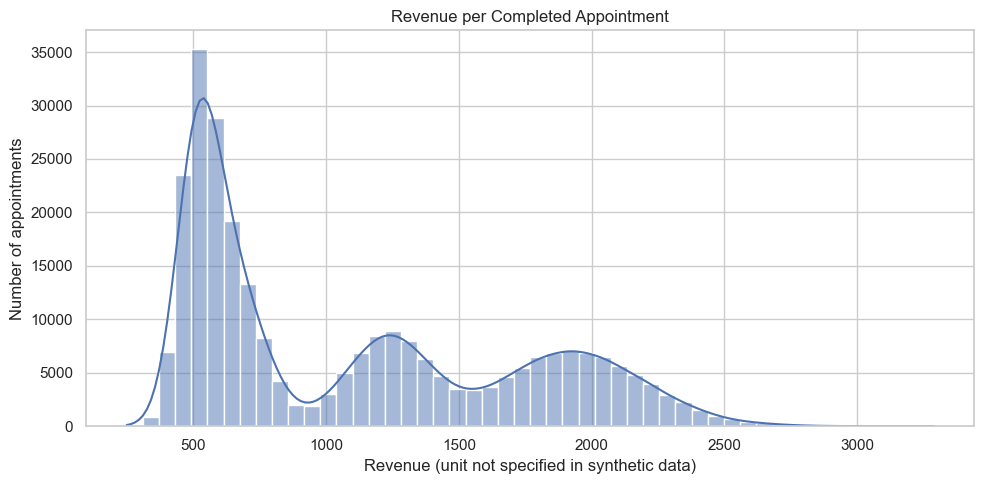

In [43]:
# Completed appointment revenue distribution

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=completed, x="revenue", bins=50, kde=True, ax=ax)
ax.set(title="Revenue per Completed Appointment",
       xlabel="Revenue (unit not specified in synthetic data)",
       ylabel="Number of appointments")
plt.tight_layout()
plt.savefig(FIGURES / "completed_appointment_revenue_distribution.png", dpi=200)
plt.show()


In [44]:
# Monthly completed appointment performance

completed["appointment_date"] = pd.to_datetime(
    completed["appointment_date"], errors="coerce"
)
completed = completed.dropna(subset=["appointment_date"]).copy()
completed["month"] = completed["appointment_date"].dt.to_period("M").dt.to_timestamp()

monthly_performance = (
    completed.groupby("month")
    .agg(
        completed_appointments=("appointment_id", "nunique"),
        total_revenue=("revenue", "sum"),
        average_revenue=("revenue", "mean"),
    )
    .reset_index()
)
display(monthly_performance)


,month,completed_appointments,total_revenue,average_revenue
0,2025-01-01,15487,16741828.5200,1081.0246
1,2025-02-01,14070,15158159.1100,1077.3390
2,2025-03-01,15514,16744174.2100,1079.2945
3,2025-04-01,15054,16109493.1800,1070.1138
4,2025-05-01,15251,16579627.3200,1087.1174
5,2025-06-01,15077,16233663.0600,1076.7171
6,2025-07-01,15545,16739434.4500,1076.8372
7,2025-08-01,15715,16903048.3500,1075.5996
8,2025-09-01,15190,16361641.6900,1077.1324
9,2025-10-01,15577,17208072.4800,1104.7103


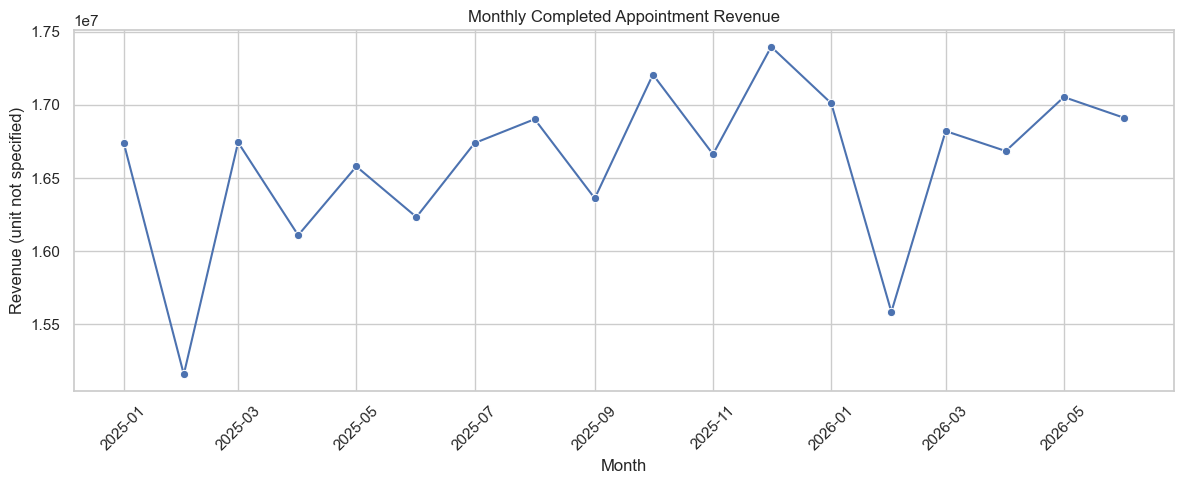

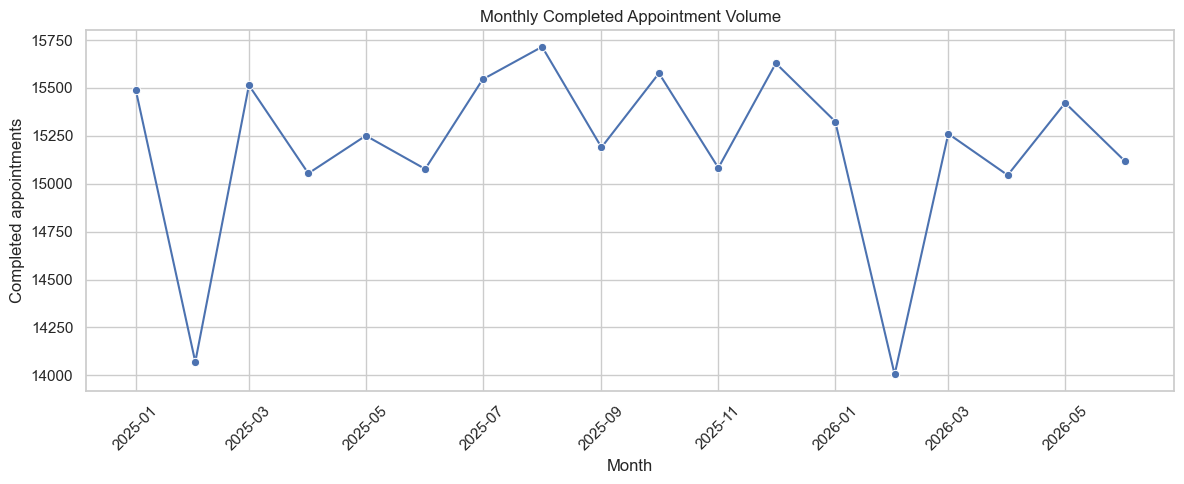

In [45]:
# Monthly revenue and completed appointment volume

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly_performance, x="month", y="total_revenue", marker="o", ax=ax)
ax.set(title="Monthly Completed Appointment Revenue",
       xlabel="Month", ylabel="Revenue (unit not specified)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / "monthly_completed_revenue.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly_performance, x="month",
             y="completed_appointments", marker="o", ax=ax)
ax.set(title="Monthly Completed Appointment Volume",
       xlabel="Month", ylabel="Completed appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / "monthly_completed_appointments.png", dpi=200)
plt.show()


# 2. Customer-level A/B Experiment Analysis

This section uses `synthetic_experiment_outcomes.csv`. It is a separate synthetic customer-level experiment scenario; it is not a randomized assignment of the 300,000 appointment rows.


In [46]:
# A/B test primary outcome

ab_test["treatment"] = ab_test["experiment_group"].eq("Treatment").astype(int)
ab_test["returned_within_60d"] = ab_test["returned_within_60d"].astype(int)

assert ab_test["customer_id"].is_unique, "A/B dataset must contain one row per customer."
assert ab_test["returned_within_60d"].notna().all(), "Primary outcome contains missing values."

ab_summary = (
    ab_test.groupby("experiment_group")["returned_within_60d"]
    .agg(customers="count", retained="sum", retention_rate="mean")
)
display(ab_summary)

control = ab_test.loc[ab_test["treatment"].eq(0), "returned_within_60d"]
treatment = ab_test.loc[ab_test["treatment"].eq(1), "returned_within_60d"]

control_rate = control.mean()
treatment_rate = treatment.mean()
absolute_effect = treatment_rate - control_rate
relative_lift = absolute_effect / control_rate * 100

successes = [int(treatment.sum()), int(control.sum())]
sample_sizes = [len(treatment), len(control)]
z_stat, p_value = proportions_ztest(successes, sample_sizes)
ci_low, ci_high = confint_proportions_2indep(
    int(treatment.sum()), len(treatment),
    int(control.sum()), len(control),
    method="newcomb", compare="diff"
)

ab_results = pd.DataFrame([{
    "control_n": len(control),
    "treatment_n": len(treatment),
    "control_retention": control_rate,
    "treatment_retention": treatment_rate,
    "absolute_effect_pp": absolute_effect * 100,
    "relative_lift_pct": relative_lift,
    "ci_95_lower_pp": ci_low * 100,
    "ci_95_upper_pp": ci_high * 100,
    "z_statistic": z_stat,
    "p_value": p_value,
}])
display(ab_results)
ab_results.to_csv(TABLES / "notebook_ab_test_results.csv", index=False)


,customers,retained,retention_rate
experiment_group,,,
Control,20006,10021,0.5009
Treatment,19994,10506,0.5255


,control_n,treatment_n,control_retention,treatment_retention,absolute_effect_pp,relative_lift_pct,ci_95_lower_pp,ci_95_upper_pp,z_statistic,p_value
0,20006,19994,0.5009,0.5255,2.4558,4.9028,1.4762,3.4347,4.9133,0.0000


# 3. Customer Segment Analysis

Subgroup p-values are adjusted using Holm's method. A treatment-by-segment interaction test is used to assess whether the treatment effect differs across segments. Statistical significance within each subgroup does not, by itself, prove that effects differ between subgroups.


In [47]:
# Segment-level treatment effects and Holm correction

segment_rows = []
for segment, subset in ab_test.groupby("customer_segment"):
    c = subset.loc[subset["treatment"].eq(0), "returned_within_60d"]
    t = subset.loc[subset["treatment"].eq(1), "returned_within_60d"]
    z, p = proportions_ztest([int(t.sum()), int(c.sum())], [len(t), len(c)])
    lo, hi = confint_proportions_2indep(
        int(t.sum()), len(t), int(c.sum()), len(c),
        method="newcomb", compare="diff"
    )
    segment_rows.append({
        "segment": segment,
        "control_n": len(c),
        "treatment_n": len(t),
        "control_retention": c.mean(),
        "treatment_retention": t.mean(),
        "effect_pp": (t.mean() - c.mean()) * 100,
        "ci_lower_pp": lo * 100,
        "ci_upper_pp": hi * 100,
        "p_value": p,
    })

segment_results = pd.DataFrame(segment_rows)
segment_results["holm_adjusted_p"] = multipletests(
    segment_results["p_value"], method="holm"
)[1]
segment_results["holm_significant"] = segment_results["holm_adjusted_p"] < 0.05
display(segment_results)
segment_results.to_csv(TABLES / "notebook_segment_effects_holm.csv", index=False)

interaction_model = smf.ols(
    "returned_within_60d ~ treatment * C(customer_segment)",
    data=ab_test
).fit(cov_type="HC2")

interaction_terms = [
    term for term in interaction_model.params.index
    if ":" in term
]
if interaction_terms:
    joint_test = interaction_model.f_test(
        ", ".join(f"{term} = 0" for term in interaction_terms)
    )
    print("Joint treatment-by-segment interaction p-value:",
          float(joint_test.pvalue))
else:
    print("No interaction terms found; verify customer_segment categories.")


,segment,control_n,treatment_n,control_retention,treatment_retention,effect_pp,ci_lower_pp,ci_upper_pp,p_value,holm_adjusted_p,holm_significant
0,Loyal,4032,3957,0.4916,0.5345,4.2928,2.1008,6.4790,0.0001,0.0004,True
1,New,6874,7003,0.5023,0.5209,1.8592,0.1958,3.5212,0.0285,0.0285,True
2,Regular,9100,9034,0.5040,0.5250,2.1061,0.6512,3.5596,0.0046,0.0091,True


Joint treatment-by-segment interaction p-value: 0.18103107084982603


# 4. CUPED Analysis

The CUPED scenario is a separate revised synthetic simulation containing a simulated pre-experiment activity covariate. It should not be combined with the original A/B dataset or described as actual historical customer activity.


In [48]:
# CUPED adjustment

cuped["treatment"] = cuped["experiment_group"].eq("Treatment").astype(int)
y = cuped["returned_within_60d"].astype(float)
x = cuped["pre_experiment_visits"].astype(float)

theta = x.cov(y) / x.var()
cuped["cuped_outcome"] = y - theta * (x - x.mean())

unadjusted_model = smf.ols(
    "returned_within_60d ~ treatment", data=cuped
).fit(cov_type="HC2")

adjusted_model = smf.ols(
    "cuped_outcome ~ treatment", data=cuped
).fit(cov_type="HC2")

variance_reduction_pct = (
    1 - cuped["cuped_outcome"].var() / y.var()
) * 100

cuped_results = pd.DataFrame([
    {
        "method": "Unadjusted",
        "effect": unadjusted_model.params["treatment"],
        "standard_error": unadjusted_model.bse["treatment"],
        "p_value": unadjusted_model.pvalues["treatment"],
    },
    {
        "method": "CUPED adjusted",
        "effect": adjusted_model.params["treatment"],
        "standard_error": adjusted_model.bse["treatment"],
        "p_value": adjusted_model.pvalues["treatment"],
    },
])
print(f"Covariate-outcome correlation: {x.corr(y):.4f}")
print(f"CUPED theta: {theta:.6f}")
print(f"Variance reduction: {variance_reduction_pct:.2f}%")
display(cuped_results)
cuped_results.to_csv(TABLES / "notebook_cuped_results.csv", index=False)


Covariate-outcome correlation: 0.1624
CUPED theta: 0.047429
Variance reduction: 2.64%


,method,effect,standard_error,p_value
0,Unadjusted,0.0255,0.0050,0.0000
1,CUPED adjusted,0.0273,0.0049,0.0000


# 5. Historical Difference-in-Differences Analysis

The outlet-month panel is a separate synthetic scenario with 22 outlets and an intervention date of July 2025. The DiD estimate is based on the difference in changes between treatment and control outlets. Only 22 clusters are available, so conventional cluster-robust inference should be interpreted cautiously.


In [49]:
# DiD group summary and fixed-effects regression

did["treatment"] = did["group"].eq("Treatment").astype(int)
did["did"] = did["treatment"] * did["post"]

did_summary = (
    did.groupby(["group", "post"])["retention_rate"]
    .agg(["mean", "count", "std"])
    .reset_index()
)
display(did_summary)

means = did.groupby(["group", "post"])["retention_rate"].mean()
manual_did = (
    (means.loc[("Treatment", 1)] - means.loc[("Treatment", 0)])
    - (means.loc[("Control", 1)] - means.loc[("Control", 0)])
)
print(f"Manual DiD estimate: {manual_did:.4f} percentage points")

did_model = smf.ols(
    "retention_rate ~ did + C(outlet_id) + C(month)",
    data=did
).fit(
    cov_type="cluster",
    cov_kwds={"groups": did["outlet_id"]}
)

did_effect = did_model.params["did"]
did_ci_low, did_ci_high = did_model.conf_int().loc["did"]
print(f"Fixed-effects DiD estimate: {did_effect:.4f} pp")
print(f"95% CI: [{did_ci_low:.4f}, {did_ci_high:.4f}]")
print(f"P-value: {did_model.pvalues['did']:.8g}")


,group,post,mean,count,std
0,Control,0,49.8804,198,10.0262
1,Control,1,54.2337,132,10.3034
2,Treatment,0,53.2325,198,8.6312
3,Treatment,1,63.4672,132,9.0566


Manual DiD estimate: 5.8814 percentage points
Fixed-effects DiD estimate: 5.8814 pp
95% CI: [4.1903, 7.5725]
P-value: 9.3252323e-12


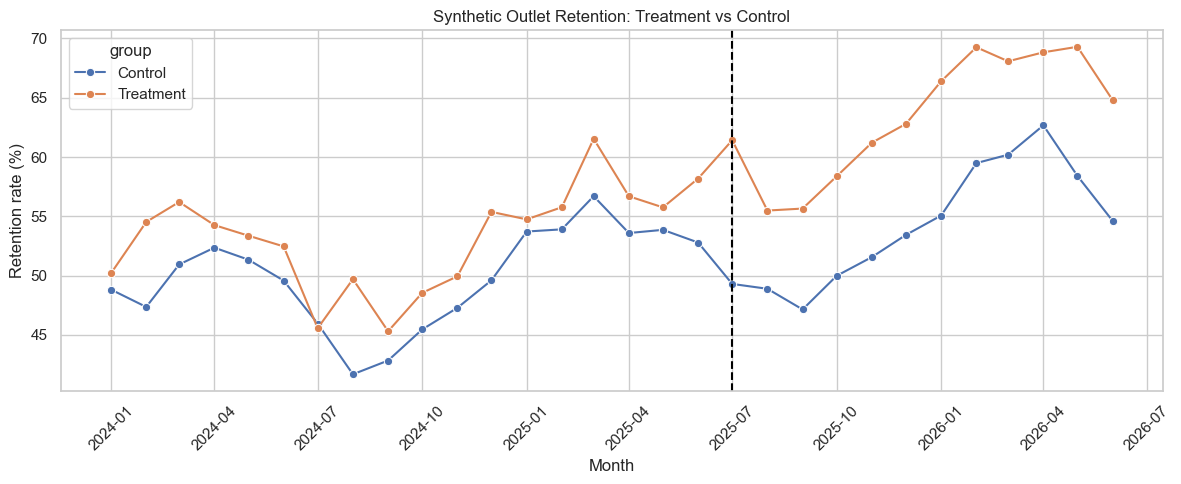

Pre-treatment trend interaction coefficient: -0.006012286966636322
Pre-treatment trend interaction p-value: 0.950877641005549


In [50]:
# DiD trend chart and pre-treatment linear trend check

trend = (
    did.groupby(["month", "group"])["retention_rate"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=trend, x="month", y="retention_rate",
             hue="group", marker="o", ax=ax)
ax.axvline(pd.Timestamp("2025-07-01"), linestyle="--",
           color="black", label="Intervention")
ax.set(title="Synthetic Outlet Retention: Treatment vs Control",
       xlabel="Month", ylabel="Retention rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / "did_parallel_trends.png", dpi=200)
plt.show()

pre = did.loc[did["post"].eq(0)].copy()
pre["time_index"] = (
    (pre["month"] - pre["month"].min()).dt.days / 30.44
)
pre["treatment_time"] = pre["treatment"] * pre["time_index"]

# Do not include treatment main effect with outlet fixed effects:
# treatment is constant within outlet and is absorbed by outlet fixed effects.
pretrend_model = smf.ols(
    "retention_rate ~ time_index + treatment_time + C(outlet_id)",
    data=pre
).fit(
    cov_type="cluster",
    cov_kwds={"groups": pre["outlet_id"]}
)

print("Pre-treatment trend interaction coefficient:",
      pretrend_model.params["treatment_time"])
print("Pre-treatment trend interaction p-value:",
      pretrend_model.pvalues["treatment_time"])


# 6. Overall Conclusions and Limitations

This notebook analyzes three distinct synthetic scenarios:

1. The 300,000-row appointment dataset for operational EDA and revenue analysis.
2. The customer-level A/B experiment and its separate CUPED simulation.
3. The outlet-month historical DiD simulation.

Do not combine their estimates into one experiment or imply that CUPED and DiD were calculated from the same randomized intervention as the original A/B test.

All findings are methodological demonstrations using synthetic data. Before a real rollout, a business would need verified customer-level randomization, actual reminder-delivery logs, pre-treatment covariates, and guardrail outcomes such as cancellation, no-show, revenue and customer opt-outs.
